# CSCU9YE Coursework – Multi-Resource Workload Allocation

**Student ID:** _30064792_

The goal is to choose which AI models to deploy (xⱼ = 1) so that the total utility is as high as possible without going over any resource limit. This is a 0-1 multidimensional knapsack problem.

- **Part 1:** a hill climber on Instance 1 (n = 28, m = 2)
- **Part 2:** a genetic algorithm on Instance 2 (n = 90, m = 5)
- **Part 3:** an experiment comparing repair with an adaptive penalty

All runs use seeds 42–71 (30 runs). The data files and `workload_data_loader.py` need to be in the same folder as this notebook.

## Setup

I use scipy's MILP solver only to get the true optimum, so I can report how far my results are from it. The LP dual prices are used later in the repair operator.

In [1]:
import glob
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import Bounds, LinearConstraint, linprog, milp

from workload_data_loader import load_workload_instance

np.random.seed(42)
SEEDS = list(range(42, 72))
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


class Instance:
    def __init__(self, stem):
        path = sorted(glob.glob(f"{stem}*.txt"))[0]
        self.name = stem
        self.n, self.m, self.p, self.R, self.b = load_workload_instance(path)

        res = milp(-self.p, constraints=LinearConstraint(self.R, -np.inf, self.b),
                   integrality=np.ones(self.n), bounds=Bounds(0, 1))
        self.opt = -res.fun

        lp = linprog(-self.p, A_ub=self.R, b_ub=self.b, bounds=(0, 1), method="highs")
        self.lp_bound, self.duals = -lp.fun, np.maximum(-lp.ineqlin.marginals, 0)


I1 = Instance("multi_resource_n28_m2")
I2 = Instance("multi_resource_n90_m5")
for inst in (I1, I2):
    print(f"{inst.name}: n={inst.n}, m={inst.m}, optimum={inst.opt:,.0f}, LP bound={inst.lp_bound:,.1f}")
    print("   capacity / total demand:", np.round(inst.b / inst.R.sum(axis=1), 2))
    print("   LP dual prices:         ", np.round(inst.duals, 2))

multi_resource_n28_m2: n=28, m=2, optimum=130,883, LP bound=131,637.5
   capacity / total demand: [0.44 0.5 ]
   LP dual prices:          [  4.4  107.28]
multi_resource_n90_m5: n=90, m=5, optimum=11,191, LP bound=11,194.7
   capacity / total demand: [0.63 0.33 0.85 0.95 0.91]
   LP dual prices:          [0.   2.77 0.   0.   0.  ]


In Instance 2, resource 2 is the bottleneck: it can only fit about a third of the total demand, and it is the only resource with a non-zero dual price.

All algorithms evaluate solutions through the `Evaluator` class. It counts the evaluations and stops at the budget, so every algorithm gets exactly the same number of evaluations.

In [2]:
class Evaluator:
    def __init__(self, inst, budget):
        self.inst, self.budget = inst, budget
        self.count = self.n_feasible = 0
        self.best, self.best_x, self.best_at = -np.inf, None, 0
        self.history = np.full(budget, np.nan)
        self.start = time.perf_counter()
        self.time_to_best = 0.0

    def done(self):
        return self.count >= self.budget

    def __call__(self, x):
        assert self.count < self.budget, "budget exceeded"
        util = float(self.inst.p @ x)
        excess = np.maximum(self.inst.R @ x - self.inst.b, 0)
        if not excess.any():
            self.n_feasible += 1
            if util > self.best:
                self.best, self.best_x, self.best_at = util, x.copy(), self.count + 1
                self.time_to_best = time.perf_counter() - self.start
        self.history[self.count] = self.best
        self.count += 1
        return util, float(excess @ (1 / self.inst.b))

## Part 1 – Hill climber

- **Representation:** a binary vector with one bit per model.
- **Starting solution:** go through the models in a random order and add each one if it fits, so the start is always feasible.
- **Moves:** *flip* switches one model on or off; *swap* removes one model and adds another. Swap matters because when the solution is nearly full, adding a model breaks a constraint and removing one loses utility, so single flips get stuck. "flip + swap" picks one of the two moves at random.
- **Acceptance:** keep the new solution if it is at least as good.

I tested three ways of handling infeasible solutions:
- **Rejection:** infeasible solutions get a fitness of −∞.
- **Static penalty:** utility − λ × (how much the capacity is exceeded), with a large fixed λ.
- **Repair:** remove the models with the lowest utility-per-resource ratio until the solution is feasible, then add the best ones that still fit. The ratio uses the LP dual prices to weight each resource (Chu & Beasley, 1998).

In [3]:
class Reject:
    name = "Rejection"

    def prepare(self, x):
        return x

    def fitness(self, util, viol):
        return util if viol == 0 else -np.inf


class StaticPenalty(Reject):
    name = "Static penalty"

    def __init__(self, inst):
        with np.errstate(divide="ignore"):
            self.lam = np.max(np.where(inst.R > 0, inst.p * inst.b[:, None] / inst.R, 0))

    def fitness(self, util, viol):
        return util - self.lam * viol


class Repair(Reject):
    name = "Repair"

    def __init__(self, inst, ratio, add=True):
        self.inst, self.ratio, self.add = inst, ratio, add
        self.calls = self.infeasible_before = 0

    def prepare(self, x):
        R, b, ratio = self.inst.R, self.inst.b, self.ratio
        load = R @ x
        self.calls += 1
        self.infeasible_before += (load > b).any()
        while (load > b).any():
            over = load > b
            cand = np.flatnonzero((x == 1) & (R[over] > 0).any(axis=0))
            j = cand[np.argmin(ratio[cand])]
            x[j] = 0
            load -= R[:, j]
        if self.add:
            fits = (x == 0) & (R <= (b - load)[:, None]).all(axis=0)
            while fits.any():
                j = np.argmax(np.where(fits, ratio, -np.inf))
                x[j] = 1
                load += R[:, j]
                fits = (x == 0) & (R <= (b - load)[:, None]).all(axis=0)
        return x


def ratios(inst, weights):
    denom = weights @ inst.R + 1e-9 * (inst.R / inst.b[:, None]).sum(axis=0)
    return inst.p / np.maximum(denom, 1e-12)

In [4]:
def random_feasible(inst, rng):
    x = np.zeros(inst.n, dtype=np.int8)
    slack = inst.b.astype(float).copy()
    for j in rng.permutation(inst.n):
        if (inst.R[:, j] <= slack).all():
            x[j] = 1
            slack -= inst.R[:, j]
    return x


def flip(x, rng):
    y = x.copy()
    y[rng.integers(len(y))] ^= 1
    return y


def swap(x, rng):
    ones, zeros = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
    if len(ones) == 0 or len(zeros) == 0:
        return flip(x, rng)
    y = x.copy()
    y[ones[rng.integers(len(ones))]] = 0
    y[zeros[rng.integers(len(zeros))]] = 1
    return y


def flip_or_swap(x, rng):
    return swap(x, rng) if rng.random() < 0.5 else flip(x, rng)

In [5]:
def hill_climber(inst, handler, move, budget, seed):
    rng = np.random.default_rng(seed)
    ev = Evaluator(inst, budget)
    x = handler.prepare(random_feasible(inst, rng))
    F = handler.fitness(*ev(x))
    while not ev.done():
        y = handler.prepare(move(x, rng))
        Fy = handler.fitness(*ev(y))
        if Fy >= F:
            x, F = y, Fy
    return ev

In [6]:
def run(algo, make_handler, seeds=SEEDS, **kwargs):
    runs = []
    for s in seeds:
        handler = make_handler()
        ev = algo(handler=handler, seed=s, **kwargs)
        ev.time = time.perf_counter() - ev.start
        ev.handler = handler
        assert np.all(ev.inst.R @ ev.best_x <= ev.inst.b)
        runs.append(ev)
    return runs


def evals_to_opt(ev):
    hit = np.flatnonzero(ev.history >= ev.inst.opt)
    return hit[0] + 1 if len(hit) else np.inf


def summary(runs):
    best = np.array([r.best for r in runs])
    opt = runs[0].inst.opt
    return {"mean": best.mean(), "std": best.std(ddof=1), "best": best.max(), "worst": best.min(),
            "mean gap %": 100 * (opt - best.mean()) / opt,
            "runs at optimum": f"{np.sum(best == opt)}/{len(runs)}",
            "median evals to best": np.median([r.best_at for r in runs]),
            "median evals to optimum": np.median([evals_to_opt(r) for r in runs]),
            "feasible evals %": 100 * np.mean([r.n_feasible / r.count for r in runs]),
            "time per run (s)": np.mean([r.time for r in runs])}


def a12(x, y):
    x, y = np.asarray(x)[:, None], np.asarray(y)[None, :]
    return ((x > y).sum() + 0.5 * (x == y).sum()) / (x.size * y.size)


def plot_convergence(ax, runs, label, color):
    opt = runs[0].inst.opt
    gap = 100 * (opt - np.array([r.history for r in runs])) / opt
    x = np.arange(1, gap.shape[1] + 1)
    ax.plot(x, np.nanmedian(gap, axis=0), color=color, label=label)
    ax.fill_between(x, *np.nanpercentile(gap, [25, 75], axis=0), color=color, alpha=0.2, lw=0)
    ax.set_xscale("log")
    ax.set_xlabel("fitness evaluations (log scale)")
    ax.set_ylabel("gap to optimum (%)")

6 combinations × 30 runs, with 5,000 evaluations per run.

In [7]:
RATIO1 = ratios(I1, I1.duals)
handlers1 = {"Rejection": lambda: Reject(),
             "Static penalty": lambda: StaticPenalty(I1),
             "Repair": lambda: Repair(I1, RATIO1)}
moves = {"flip": flip, "flip + swap": flip_or_swap}

p1 = {}
for move_name, move in moves.items():
    for h_name, make in handlers1.items():
        p1[(move_name, h_name)] = run(hill_climber, make, inst=I1, move=move, budget=5000)

table1 = pd.DataFrame({k: summary(v) for k, v in p1.items()}).T.drop(columns="median evals to optimum")
table1

mean        std        best       worst  \
flip        Rejection       77,967.400 15,571.165 111,430.000  48,530.000   
            Static penalty  82,147.700 13,832.169 111,430.000  58,131.000   
            Repair         130,723.000      0.000 130,723.000 130,723.000   
flip + swap Rejection      106,363.467  9,661.622 121,653.000  89,272.000   
            Static penalty 110,934.067  9,587.711 128,602.000  89,272.000   
            Repair         130,883.000      0.000 130,883.000 130,883.000   

                           mean gap % runs at optimum median evals to best  \
flip        Rejection          40.430            0/30                1.000   
            Static penalty     37.236            0/30                1.000   
            Repair              0.122            0/30               32.000   
flip + swap Rejection          18.734            0/30              497.500   
            Static penalty     15.242            0/30              574.000   
            Repair              0.000           30/30              373.500   

                           feasible evals % time per run (s)  
flip        Rejection                53.757            0.048  
            Static penalty           56.285            0.048  
            Repair                  100.000            0.195  
flip + swap Rejection                42.646            0.092  
            Static penalty           42.844            0.060  
            Repair                  100.000            0.181

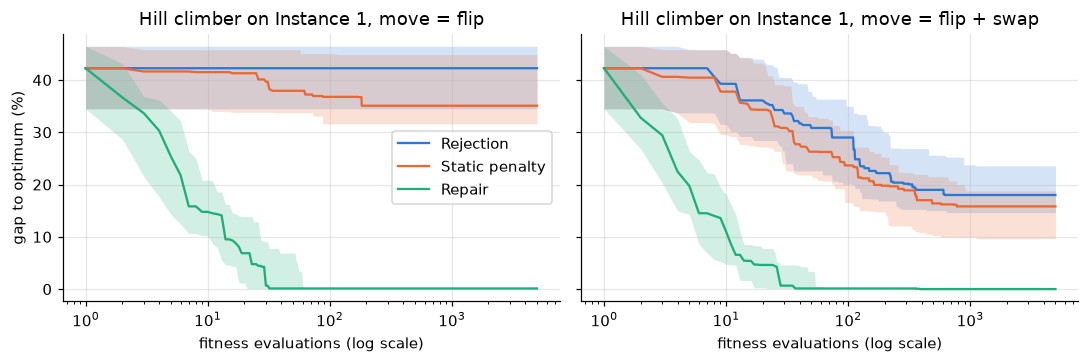

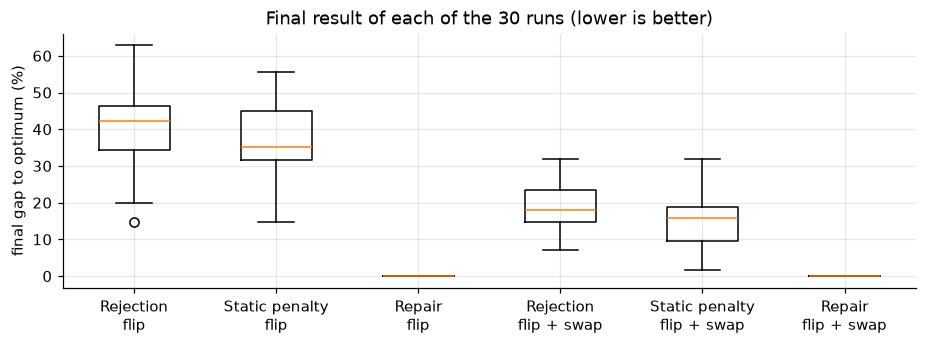

Best solution found: 130,883 | selected models: [3, 5, 7, 8, 10, 11, 14, 19, 21, 23, 24]
Resource use: [495. 499.] of [500. 500.]
For comparison, the greedy repair on its own (empty start, no search) gives 130,723


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, move_name in zip(axes, moves):
    for color, h_name in zip(COLORS, handlers1):
        plot_convergence(ax, p1[(move_name, h_name)], h_name, color)
    ax.set_title(f"Hill climber on Instance 1, move = {move_name}")
axes[1].set_ylabel("")
axes[0].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
labels = [f"{h}\n{mv}" for mv, h in p1]
ax.boxplot([[100 * (I1.opt - r.best) / I1.opt for r in runs] for runs in p1.values()])
ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_ylabel("final gap to optimum (%)")
ax.set_title("Final result of each of the 30 runs (lower is better)")
plt.show()

best = max(p1[("flip + swap", "Repair")], key=lambda r: r.best)
print(f"Best solution found: {best.best:,.0f} | selected models: {(np.flatnonzero(best.best_x) + 1).tolist()}")
print("Resource use:", I1.R @ best.best_x, "of", I1.b)
greedy1 = Repair(I1, RATIO1).prepare(np.zeros(I1.n, dtype=np.int8))
print(f"For comparison, the greedy repair on its own (empty start, no search) gives {I1.p @ greedy1:,.0f}")

### Results

Repair with flip + swap found the optimum (130,883) in all 30 runs. With flips only, everything got stuck: rejection mostly never improved on the starting solution, and repair always ended at 130,723, which is just the greedy solution. Even with swaps, rejection and the static penalty stayed 15–19% below the optimum, because more than half of their evaluations were spent on infeasible solutions. Repair is slower per run but still fast, so I used it in Part 2.

## Part 2 – Genetic algorithm

I used a steady-state GA with repair, based on Chu & Beasley (1998):
- a population of 100 different random feasible solutions
- binary tournament selection
- uniform crossover (the order of the models doesn't mean anything, so there's no reason to use 1-point crossover)
- bit-flip mutation with rate 2/n
- every child is repaired, then replaces the worst member if it is at least as good and not a duplicate

Constraint handling is a separate object, so the same GA can be used with a penalty in Part 3.

In [9]:
def tournament(F, rng):
    i, j = rng.integers(len(F), size=2)
    return i if F[i] >= F[j] else j


def genetic_algorithm(inst, handler, budget, seed, pop_size=100):
    rng = np.random.default_rng(seed)
    ev = Evaluator(inst, budget)
    mut_rate = 2 / inst.n


    pop, util, viol, seen = [], [], [], set()
    while len(pop) < pop_size:
        x = handler.prepare(random_feasible(inst, rng))
        if x.tobytes() in seen:
            continue
        u, v = ev(x)
        pop.append(x); util.append(u); viol.append(v); seen.add(x.tobytes())
    pop, util, viol = np.array(pop), np.array(util), np.array(viol)
    F = np.array([handler.fitness(u, v) for u, v in zip(util, viol)])

    children = 0
    while not ev.done():
        a, b = tournament(F, rng), tournament(F, rng)
        child = np.where(rng.random(inst.n) < 0.5, pop[a], pop[b]).astype(np.int8)
        child[rng.random(inst.n) < mut_rate] ^= 1
        child = handler.prepare(child)
        u, v = ev(child)
        Fc = handler.fitness(u, v)
        w = np.argmin(F)
        if child.tobytes() not in seen and Fc >= F[w]:
            seen.discard(pop[w].tobytes())
            seen.add(child.tobytes())
            pop[w], util[w], viol[w], F[w] = child, u, v, Fc
        children += 1
        if children % pop_size == 0 and hasattr(handler, "update"):
            handler.update(viol[np.argmax(F)] == 0)
            F = util - handler.lam * viol
    return ev

In [10]:
RATIO2_LP = ratios(I2, I2.duals)
RATIO2_NORM = ratios(I2, 1 / I2.b)
for name, r in [("LP-dual ratio", RATIO2_LP), ("normalised ratio", RATIO2_NORM)]:
    greedy = Repair(I2, r).prepare(np.zeros(I2.n, dtype=np.int8))
    print(f"Greedy only (no search), {name}: {I2.p @ greedy:,.0f}  "
          f"(gap {100 * (I2.opt - I2.p @ greedy) / I2.opt:.2f}%)")

Greedy only (no search), LP-dual ratio: 11,167  (gap 0.21%)
Greedy only (no search), normalised ratio: 10,819  (gap 3.32%)


The greedy repair on its own is already only 0.21% from the optimum, so I checked whether the GA actually helps. I compared it with the hill climber using the LP-dual repair and a weaker "normalised" repair that doesn't use the LP (30 runs, 20,000 evaluations each).

In [11]:
repairs2 = {"LP-dual repair": lambda: Repair(I2, RATIO2_LP),
            "Normalised repair": lambda: Repair(I2, RATIO2_NORM)}
p2 = {}
for r_name, make in repairs2.items():
    p2[(r_name, "GA")] = run(genetic_algorithm, make, inst=I2, budget=20000)
    p2[(r_name, "HC")] = run(hill_climber, make, inst=I2, move=flip_or_swap, budget=20000)

table2 = pd.DataFrame({k: summary(v) for k, v in p2.items()}).T.drop(columns=["median evals to best", "feasible evals %"])
table2

mean   std       best      worst mean gap %  \
LP-dual repair    GA 11,191.000 0.000 11,191.000 11,191.000      0.000   
                  HC 11,191.000 0.000 11,191.000 11,191.000      0.000   
Normalised repair GA 11,191.000 0.000 11,191.000 11,191.000      0.000   
                  HC 11,188.333 1.918 11,191.000 11,187.000      0.024   

                     runs at optimum median evals to optimum time per run (s)  
LP-dual repair    GA           30/30                 477.000            1.167  
                  HC           30/30                 589.500            0.638  
Normalised repair GA           30/30                 894.500            1.181  
                  HC           10/30                     inf            0.803

LP-dual repair: GA better than HC?  Mann-Whitney p = 1.00e+00,  A12 = 0.50
Normalised repair: GA better than HC?  Mann-Whitney p = 2.94e-08,  A12 = 0.83


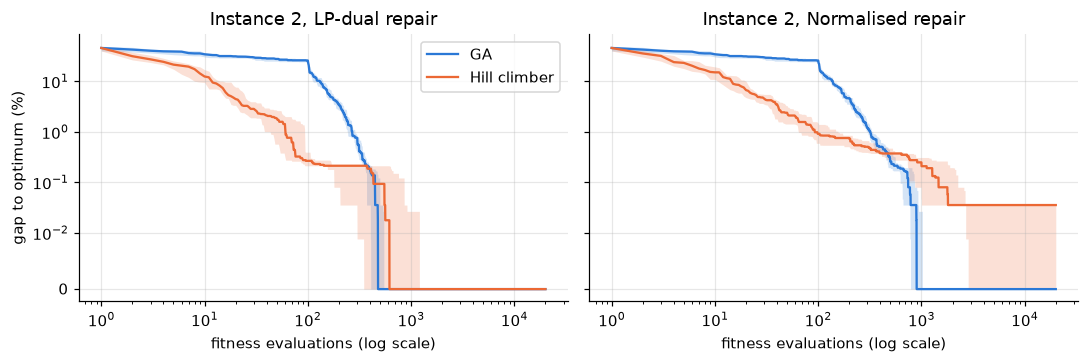

In [12]:
for r_name in repairs2:
    ga = [r.best for r in p2[(r_name, "GA")]]
    hc = [r.best for r in p2[(r_name, "HC")]]
    p = stats.mannwhitneyu(ga, hc, alternative="greater").pvalue if len(set(ga + hc)) > 1 else 1.0
    print(f"{r_name}: GA better than HC?  Mann-Whitney p = {p:.2e},  A12 = {a12(ga, hc):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, r_name in zip(axes, repairs2):
    plot_convergence(ax, p2[(r_name, "GA")], "GA", COLORS[0])
    plot_convergence(ax, p2[(r_name, "HC")], "Hill climber", COLORS[1])
    ax.set_yscale("symlog", linthresh=0.01)
    ax.set_title(f"Instance 2, {r_name}")
axes[1].set_ylabel("")
axes[0].legend()
plt.tight_layout()
plt.show()

### Results

With the LP-dual repair, both algorithms found the optimum in all 30 runs, so this instance is fairly easy. With the normalised repair, the GA still found it in 30/30 runs but the hill climber only managed 10/30 (p = 2.9 × 10⁻⁸, A12 = 0.83). The GA is more robust because crossover combines different solutions, while the hill climber can only follow one path. The GA starts slower because it first has to evaluate the initial population.

## Part 3 – Repair vs adaptive penalty

I compared two versions of the same GA that only differ in how they handle constraints:
- **A:** repair (from Part 2)
- **B:** an adaptive penalty (Hadj-Alouane & Bean, 1997): utility − λ × violation, where λ is divided by 1.5 after a generation in which the best solution is feasible, and doubled when it is not.

**Hypothesis:** A reaches the optimum in fewer evaluations than B, because B wastes evaluations on infeasible children while A repairs every child.

**Setup:** 30 runs each, the same seeds and 20,000 evaluations per run. I picked B's starting λ from three values tested on separate seeds (1000–1009). For the statistics I used one-sided Mann–Whitney U tests with A12 effect sizes and a Bonferroni correction for the 4 tests.

In [13]:
class AdaptivePenalty(StaticPenalty):
    name = "Adaptive penalty"

    def __init__(self, lam0):
        self.lam = lam0

    def update(self, best_is_feasible):
        self.lam = self.lam / 1.5 if best_is_feasible else self.lam * 2


PILOT_SEEDS = list(range(1000, 1010))
for mult in [0.1, 1, 10]:
    pilot = run(genetic_algorithm, lambda: AdaptivePenalty(mult * I2.p.sum()),
                seeds=PILOT_SEEDS, inst=I2, budget=20000)
    print(f"lam0 = {mult:>4} x sum(p): average best-so-far over the run = "
          f"{np.mean([np.nanmean(r.history) for r in pilot]):,.1f}, "
          f"reached optimum {sum(r.best == I2.opt for r in pilot)}/10")

lam0 =  0.1 x sum(p): average best-so-far over the run = 11,060.1, reached optimum 10/10
lam0 =    1 x sum(p): average best-so-far over the run = 11,054.3, reached optimum 10/10
lam0 =   10 x sum(p): average best-so-far over the run = 11,046.1, reached optimum 10/10


The three values give similar results, so I used λ₀ = 0.1 × Σp.

In [14]:
LAM0 = 0.1 * I2.p.sum()
runs_A = p2[("LP-dual repair", "GA")]
runs_B = run(genetic_algorithm, lambda: AdaptivePenalty(LAM0), inst=I2, budget=20000)
assert all(r.count == 20000 for r in runs_A + runs_B)

pd.DataFrame({"A: repair GA": summary(runs_A), "B: penalty GA": summary(runs_B)}).T[
    ["mean", "std", "worst", "mean gap %", "runs at optimum", "median evals to optimum"]]

,mean,std,worst,mean gap %,runs at optimum,median evals to optimum
A: repair GA,"11,191.000",0.000,"11,191.000",0.000,30/30,477.000
B: penalty GA,"11,189.367",6.139,"11,160.000",0.015,27/30,"9,560.000"


In [15]:
def compare(name, a, b, a_better):
    alt = "less" if a_better == "lower" else "greater"
    p = stats.mannwhitneyu(a, b, alternative=alt).pvalue
    A12 = a12(b, a) if a_better == "lower" else a12(a, b)
    return {"test": name, "A median": np.median(a), "B median": np.median(b),
            "p-value": f"{p:.2e}", "Bonferroni p (x4)": f"{min(1, 4 * p):.2e}",
            "A12 (A better)": round(A12, 2)}


tests = [compare("evaluations to optimum", [evals_to_opt(r) for r in runs_A],
                 [evals_to_opt(r) for r in runs_B], "lower")]
for t in [1000, 5000, 20000]:
    tests.append(compare(f"utility after {t:,} evals", [r.history[t - 1] for r in runs_A],
                         [r.history[t - 1] for r in runs_B], "higher"))
pd.DataFrame(tests).set_index("test")

,A median,B median,p-value,Bonferroni p (x4),A12 (A better)
test,,,,,
evaluations to optimum,477.000,"9,560.000",1.51e-11,6.02e-11,1.000
"utility after 1,000 evals","11,191.000","10,465.500",6.06e-13,2.42e-12,1.000
"utility after 5,000 evals","11,191.000","11,153.500",2.86e-11,1.15e-10,0.950
"utility after 20,000 evals","11,191.000","11,191.000",4.08e-02,1.63e-01,0.550


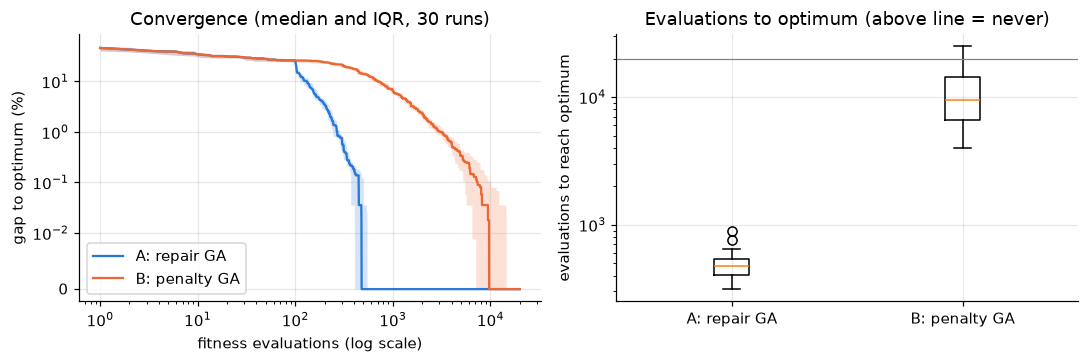

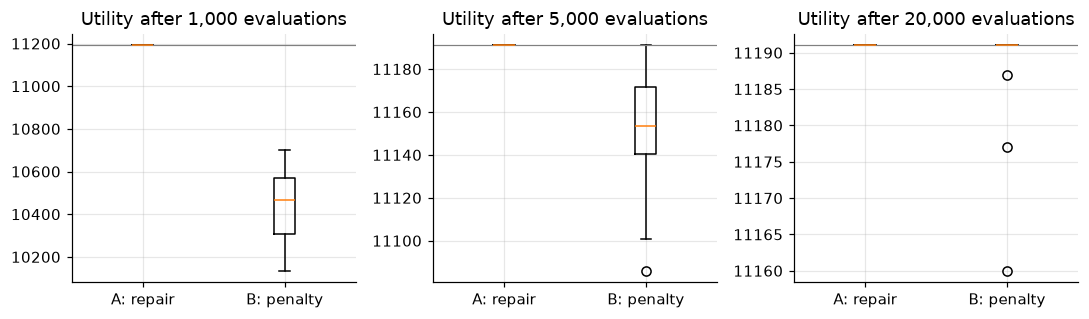

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_convergence(axes[0], runs_A, "A: repair GA", COLORS[0])
plot_convergence(axes[0], runs_B, "B: penalty GA", COLORS[1])
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_title("Convergence (median and IQR, 30 runs)")
axes[0].legend()
hits = [[min(evals_to_opt(r), 25000) for r in runs] for runs in (runs_A, runs_B)]
axes[1].boxplot(hits)
axes[1].set_xticks([1, 2], ["A: repair GA", "B: penalty GA"])
axes[1].axhline(20000, color="grey", lw=0.8)
axes[1].set_yscale("log")
axes[1].set_ylabel("evaluations to reach optimum")
axes[1].set_title("Evaluations to optimum (above line = never)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, t in zip(axes, [1000, 5000, 20000]):
    ax.boxplot([[r.history[t - 1] for r in runs_A], [r.history[t - 1] for r in runs_B]])
    ax.set_xticks([1, 2], ["A: repair", "B: penalty"])
    ax.axhline(I2.opt, color="grey", lw=0.8)
    ax.set_title(f"Utility after {t:,} evaluations")
plt.tight_layout()
plt.show()

In [17]:
cost = pd.DataFrame({
    name: {"feasible evaluations %": 100 * np.mean([r.n_feasible / r.count for r in runs]),
           "time per run (s)": np.median([r.time for r in runs]),
           "time per evaluation (microseconds)": 1e6 * np.median([r.time / r.count for r in runs]),
           "time to optimum (s, runs that reached it)":
               np.median([r.time_to_best for r in runs if r.best == I2.opt])}
    for name, runs in [("A: repair GA", runs_A), ("B: penalty GA", runs_B)]}).T
print("Repair: share of children that were already feasible before repair = "
      f"{100 * np.mean([1 - r.handler.infeasible_before / r.handler.calls for r in runs_A]):.0f}%")
cost

Repair: share of children that were already feasible before repair = 42%


,feasible evaluations %,time per run (s),time per evaluation (microseconds),"time to optimum (s, runs that reached it)"
A: repair GA,100.000,1.133,56.652,0.039
B: penalty GA,39.387,0.492,24.595,0.235


### Results

The hypothesis is supported. A needed a median of 477 evaluations to reach the optimum, while B needed 9,560 (p = 1.5 × 10⁻¹¹, A12 = 1.00). A found the optimum in 30/30 runs, B in 27/30.

A was also significantly better after 1,000 and 5,000 evaluations, but after 20,000 the difference was not significant (Bonferroni p = 0.16). So repair mainly gets to the optimum faster; it doesn't end up better.

About 60% of B's evaluations were on infeasible solutions, while A never wastes an evaluation. Repair makes each evaluation about twice as slow, but A still reached the optimum about 6 times sooner in real time.

**Trade-offs:** repair gets to the optimum faster but needs a problem-specific heuristic. The penalty is simpler and needs no knowledge of the problem, but it wastes evaluations and λ has to be set.

**Limitations:** I only used one instance, and it is an easy one with a single bottleneck resource. I also only tuned the starting λ.

## References

- Chu, P. C. & Beasley, J. E. (1998). A genetic algorithm for the multidimensional knapsack problem. *Journal of Heuristics*, 4(1), 63–86.
- Hadj-Alouane, A. B. & Bean, J. C. (1997). A genetic algorithm for the multiple-choice integer program. *Operations Research*, 45(1), 92–101.
- Vargha, A. & Delaney, H. D. (2000). A critique and improvement of the CL common language effect size statistics of McGraw and Wong. *Journal of Educational and Behavioral Statistics*, 25(2), 101–132.